## 1. Setup

In [1]:
import os, random, math
import numpy as np
import matplotlib.pyplot as plt

from glob import glob
from PIL import Image
from tifffile import imwrite

from skimage.filters import threshold_otsu, gaussian
from skimage.morphology import remove_small_objects, remove_small_holes
from skimage.transform import resize, rotate

SEED = 42
random.seed(SEED); np.random.seed(SEED)

import os

for folder in [SINGLE_PARTICLE_FOLDER, OVERLAPPING_PARTICLE_FOLDER]:
    print(f"\nFolder: {folder}")

    for root, dirs, files in os.walk(folder):
        print(f"\nLocation: {root}")
        print("Subfolders:", dirs[:10])
        print("Files:", files[:15])

        # Avoid printing every subfolder in a huge dataset
        if root.count(os.sep) - folder.count(os.sep) >= 2:
            dirs[:] = []

NameError: name 'SINGLE_PARTICLE_FOLDER' is not defined

## 2. Config

Point `INPUT_FOLDER` at the folder of single-particle BMPs (same source you used in `01_data_setup.ipynb`,
e.g. the extracted `Single Particle Dataset` folder). `BACKGROUND_LEVEL` and `BACKGROUND_NOISE_STD` were
measured directly from your reference photo (`1_3.jpg`) — adjust if you generate stats from a different
reference frame.


In [ ]:
import os
from glob import glob

# Input folders
SINGLE_PARTICLE_FOLDER = "images/single_particles/single"
OVERLAPPING_PARTICLE_FOLDER = "images/overlap_images"

# Output folders
OUTPUT_IMAGE_FOLDER = "dataset/images"
OUTPUT_MASK_FOLDER = "dataset/masks"

os.makedirs(OUTPUT_IMAGE_FOLDER, exist_ok=True)
os.makedirs(OUTPUT_MASK_FOLDER, exist_ok=True)

# Find single-particle BMP files
single_files = glob(
    os.path.join(SINGLE_PARTICLE_FOLDER, "*.bmp")
)

# Find overlapping TIFF files
overlap_files = glob(
    os.path.join(OVERLAPPING_PARTICLE_FOLDER, "*.tif")
)

print("Single-particle BMP files:", len(single_files))
print("Overlapping TIFF files:", len(overlap_files))

# Use single particles for particle extraction
INPUT_FOLDER = SINGLE_PARTICLE_FOLDER
particle_files = single_files

Single-particle BMP files: 3626
Overlapping TIFF files: 100


## 3. Extract Particles from Source BMPs

Same segmentation logic as your `extract_particle()` cell — dark particle on light background,
Otsu threshold with `img < threshold` (correct polarity, **no inversion**). The only change is we keep
the crop's true background pixels out of the composite later via masking, not by zeroing them here,
so nothing about particle intensity is altered.


In [ ]:
def extract_particle(file, padding=4):
    # 1. Load the image in grayscale and normalise pixels to [0, 1]
    img = (
        np.array(Image.open(file).convert("L"))
        .astype(np.float32) / 255.0
    )

    # 2. Identify dark particles against a light background
    threshold = threshold_otsu(img)
    mask = img < threshold

    # 3. Clean the binary mask
    mask = remove_small_objects(mask, min_size=30)
    mask = remove_small_holes(mask, area_threshold=30)

    # 4. Return None if no foreground pixels remain
    if not mask.any():
        return None

    # 5. Find the particle's bounding box
    coords = np.argwhere(mask)
    y1, x1 = coords.min(axis=0)
    y2, x2 = coords.max(axis=0)

    # 6. Add padding without going outside the image
    y1 = max(0, y1 - padding)
    x1 = max(0, x1 - padding)
    y2 = min(img.shape[0], y2 + padding + 1)
    x2 = min(img.shape[1], x2 + padding + 1)

    # 7. Crop the original image and its corresponding mask
    img_crop = img[y1:y2, x1:x2]
    mask_crop = mask[y1:y2, x1:x2]

    return img_crop, mask_crop


# Find all BMP files in the input folder
particle_files = glob(os.path.join(INPUT_FOLDER, "*.bmp"))

print("BMP files found:", len(particle_files))

# Extract particles
particles = []

for f in particle_files:
    result = extract_particle(f)

    if result is not None:
        particles.append(result)

print("Particles loaded:", len(particles))

if len(particles) == 0:
    raise ValueError(
        "No particles extracted. Check INPUT_FOLDER "
        "and threshold polarity."
    )

BMP files found: 3626
Particles loaded: 3626


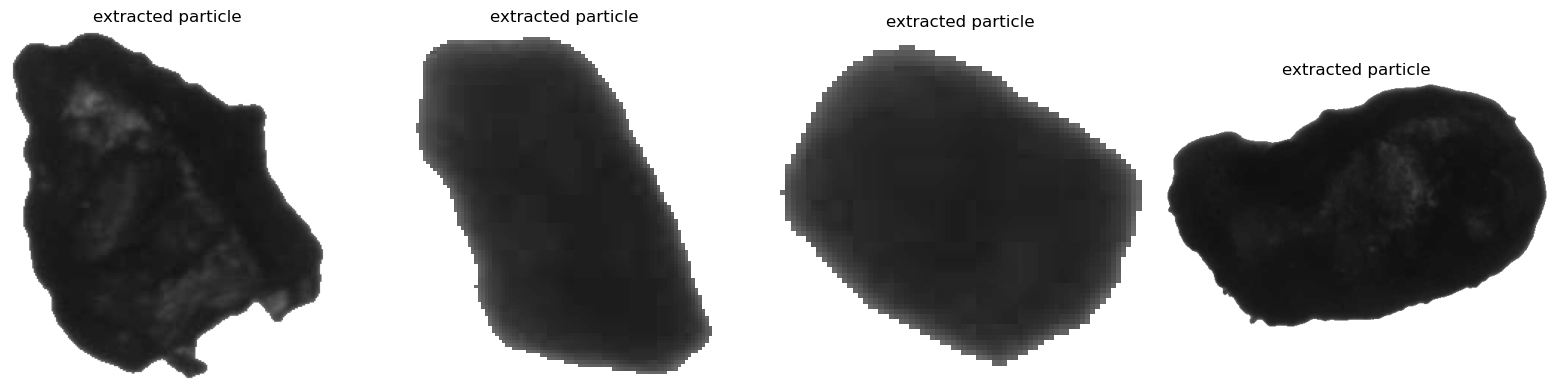

In [ ]:
# sanity check: extracted particle should still look dark-on-light, same as source, not inverted
fig, axes = plt.subplots(1, min(4, len(particles)), figsize=(4 * min(4, len(particles)), 4))
if min(4, len(particles)) == 1:
    axes = [axes]
for ax, (img_p, mask_p) in zip(axes, particles[:4]):
    ax.imshow(img_p, cmap="gray", vmin=0, vmax=1)
    ax.set_title("extracted particle")
    ax.axis("off")
plt.tight_layout(); plt.show()


## 4. Random Particle Transform (resize + rotate, no color change)

In [ ]:

import math
import random
import numpy as np
from skimage.transform import resize, rotate
from skimage.filters import gaussian

def sample_size(lo=3, hi=150):
    if lo <= 0 or hi < lo:
        raise ValueError("Require 0 < lo <= hi")
    return math.exp(random.uniform(math.log(lo), math.log(hi)))

def transform_particle(img, mask):
    h, w = img.shape
    longer = sample_size()
    s = longer / max(h, w)

    sy = random.uniform(0.5, 1.6)
    sx = random.uniform(0.5, 1.6)
    nh = max(2, round(h * s * sy))
    nw = max(2, round(w * s * sx))

    img_r = resize(img, (nh, nw), preserve_range=True,
                   anti_aliasing=True)
    mask_r = resize(mask.astype(float), (nh, nw),
                    preserve_range=True, order=0,
                    anti_aliasing=False) > 0.5

    angle = random.randint(0, 360)
    img_r = rotate(img_r, angle, resize=True,
                   preserve_range=True, mode="constant",
                   cval=0.9)
    mask_r = rotate(mask_r.astype(float), angle,
                    resize=True, preserve_range=True,
                    order=0, mode="constant", cval=0) > 0.5

    coords = np.argwhere(mask_r)
    if len(coords) < 3:
        return None

    y1, x1 = coords.min(axis=0)
    y2, x2 = coords.max(axis=0)
    img_r = img_r[y1:y2 + 1, x1:x2 + 1]
    mask_r = mask_r[y1:y2 + 1, x1:x2 + 1]

    if random.random() < 0.3:
        sigma = random.uniform(0.6, 1.2) + longer * random.uniform(0, 0.05)
        img_r = gaussian(img_r, sigma=sigma, preserve_range=True)

    return img_r, mask_r

print("SUCCESS: Both functions are defined.")
print("Sample size:", sample_size())


SUCCESS: Both functions are defined.
Sample size: 33.95341401881781


## 5. Composite Synthetic Image

The key fix vs. the earlier notebook: the canvas starts at `BACKGROUND_LEVEL` (light gray, matching your
real images) plus a touch of matching background noise — **not** `np.zeros(...)` (black). Each particle
is pasted only where its mask is `True`, so the surrounding canvas keeps the correct light background
instead of turning black, and particle grey values are pasted exactly as extracted (never inverted).


Synthetic image settings loaded!
PARTICLES_RANGE: (10, 50)


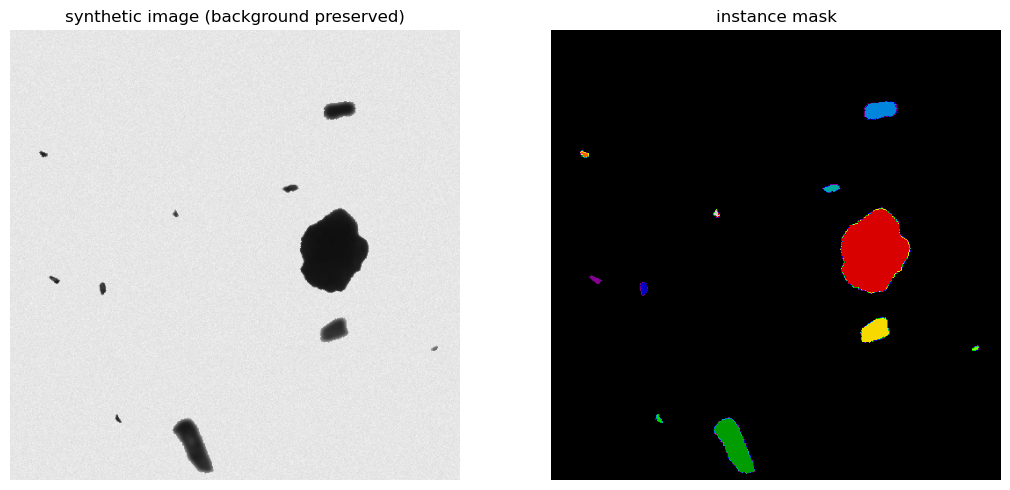

In [ ]:

# Image generation settings
BACKGROUND_LEVEL = 0.9    # light grey background level (matches real frames)
    BACKGROUND_NOISE_STD = 0.02  # per-pixel noise std
    IMAGE_SIZE = 512             # square image (512x512)

    print('Synthetic image settings loaded!')

    # Minimum and maximum number of particles per synthetic image
    PARTICLES_RANGE = (10, 50)

    print('PARTICLES_RANGE:', PARTICLES_RANGE)

    OVERLAP_PROBABILITY = 0.1   # if overlap > 0, skip this placement with this probability

    def create_synthetic_image():
        canvas = np.random.normal(BACKGROUND_LEVEL, BACKGROUND_NOISE_STD, (IMAGE_SIZE, IMAGE_SIZE)).astype(np.float32)
        canvas = np.clip(canvas, 0, 1)
        instance_mask = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint16)

        n_target = random.randint(*PARTICLES_RANGE)
        particle_id = 1
        attempts = 0

        while particle_id <= n_target:
            attempts += 1
            if attempts > 40000:
                break

            img_p, mask_p = random.choice(particles)
            result = transform_particle(img_p, mask_p)
            if result is None:
                continue
            img_p, mask_p = result

            h, w = mask_p.shape
            if h >= IMAGE_SIZE or w >= IMAGE_SIZE:
                continue

            y = random.randint(0, IMAGE_SIZE - h - 1)
            x = random.randint(0, IMAGE_SIZE - w - 1)

            existing = instance_mask[y:y + h, x:x + w]
            overlap = np.sum(existing[mask_p] > 0)
            if overlap > 0 and random.random() > OVERLAP_PROBABILITY:
                continue

            canvas_region = canvas[y:y + h, x:x + w]
            canvas_region[mask_p] = img_p[mask_p]     # paste TRUE particle grey values
            canvas[y:y + h, x:x + w] = canvas_region

            mask_region = instance_mask[y:y + h, x:x + w]
            mask_region[mask_p] = particle_id
            instance_mask[y:y + h, x:x + w] = mask_region

            particle_id += 1

        return canvas, instance_mask


    image, mask = create_synthetic_image()

    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    ax[0].imshow(image, cmap='gray', vmin=0, vmax=1)
    ax[0].set_title('synthetic image (background preserved)')
    ax[0].axis('off')
    ax[1].imshow(mask, cmap='nipy_spectral')
    ax[1].set_title('instance mask')
    ax[1].axis('off')
    plt.tight_layout(); plt.show()


## 6. Side-by-side Sanity Check Against the Real Reference Image

In [ ]:
# upload/point this at your reference frame (e.g. 1_3.jpg) to visually confirm the background/particle
# polarity now matches -- both should show light gray background with dark irregular particles.
REAL_REFERENCE_IMAGE = "/content/1_3.jpg"   # adjust path if needed

if os.path.exists(REAL_REFERENCE_IMAGE):
    real_img = np.array(Image.open(REAL_REFERENCE_IMAGE).convert("L")).astype(np.float32) / 255.0
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    ax[0].imshow(real_img, cmap="gray", vmin=0, vmax=1); ax[0].set_title("real reference"); ax[0].axis("off")
    ax[1].imshow(image, cmap="gray", vmin=0, vmax=1); ax[1].set_title("synthetic (this notebook)"); ax[1].axis("off")
    plt.tight_layout(); plt.show()
else:
    print(f"Reference image not found at {REAL_REFERENCE_IMAGE} -- skipping comparison plot.")


Reference image not found at /content/1_3.jpg -- skipping comparison plot.


## 7. Generate and Save the Full Synthetic Dataset

In [ ]:
NUMBER_OF_IMAGES = 500
    for i in range(NUMBER_OF_IMAGES):
        image, mask = create_synthetic_image()

        imwrite(f"{OUTPUT_IMAGE_FOLDER}/image_{i:03d}.tif", image.astype(np.float32))
        imwrite(f"{OUTPUT_MASK_FOLDER}/mask_{i:03d}.tif", mask.astype(np.uint16))

        if (i + 1) % 10 == 0 or i == NUMBER_OF_IMAGES - 1:
            print(f"Generated {i + 1}/{NUMBER_OF_IMAGES}")

    print('Done. Saved to:', OUTPUT_IMAGE_FOLDER, 'and', OUTPUT_MASK_FOLDER)


Generated 10/500
Generated 20/500
Generated 30/500
Generated 40/500
Generated 50/500
Generated 60/500
Generated 70/500
Generated 80/500
Generated 90/500
Generated 100/500
Generated 110/500
Generated 120/500
Generated 130/500
Generated 140/500
Generated 150/500
Generated 160/500
Generated 170/500
Generated 180/500
Generated 190/500
Generated 200/500
Generated 210/500
Generated 220/500
Generated 230/500
Generated 240/500
Generated 250/500
Generated 260/500
Generated 270/500
Generated 280/500
Generated 290/500
Generated 300/500
Generated 310/500
Generated 320/500
Generated 330/500
Generated 340/500
Generated 350/500
Generated 360/500
Generated 370/500
Generated 380/500
Generated 390/500
Generated 400/500
Generated 410/500
Generated 420/500
Generated 430/500
Generated 440/500
Generated 450/500
Generated 460/500
Generated 470/500
Generated 480/500
Generated 490/500
Generated 500/500
Done. Saved to: dataset/images and dataset/masks


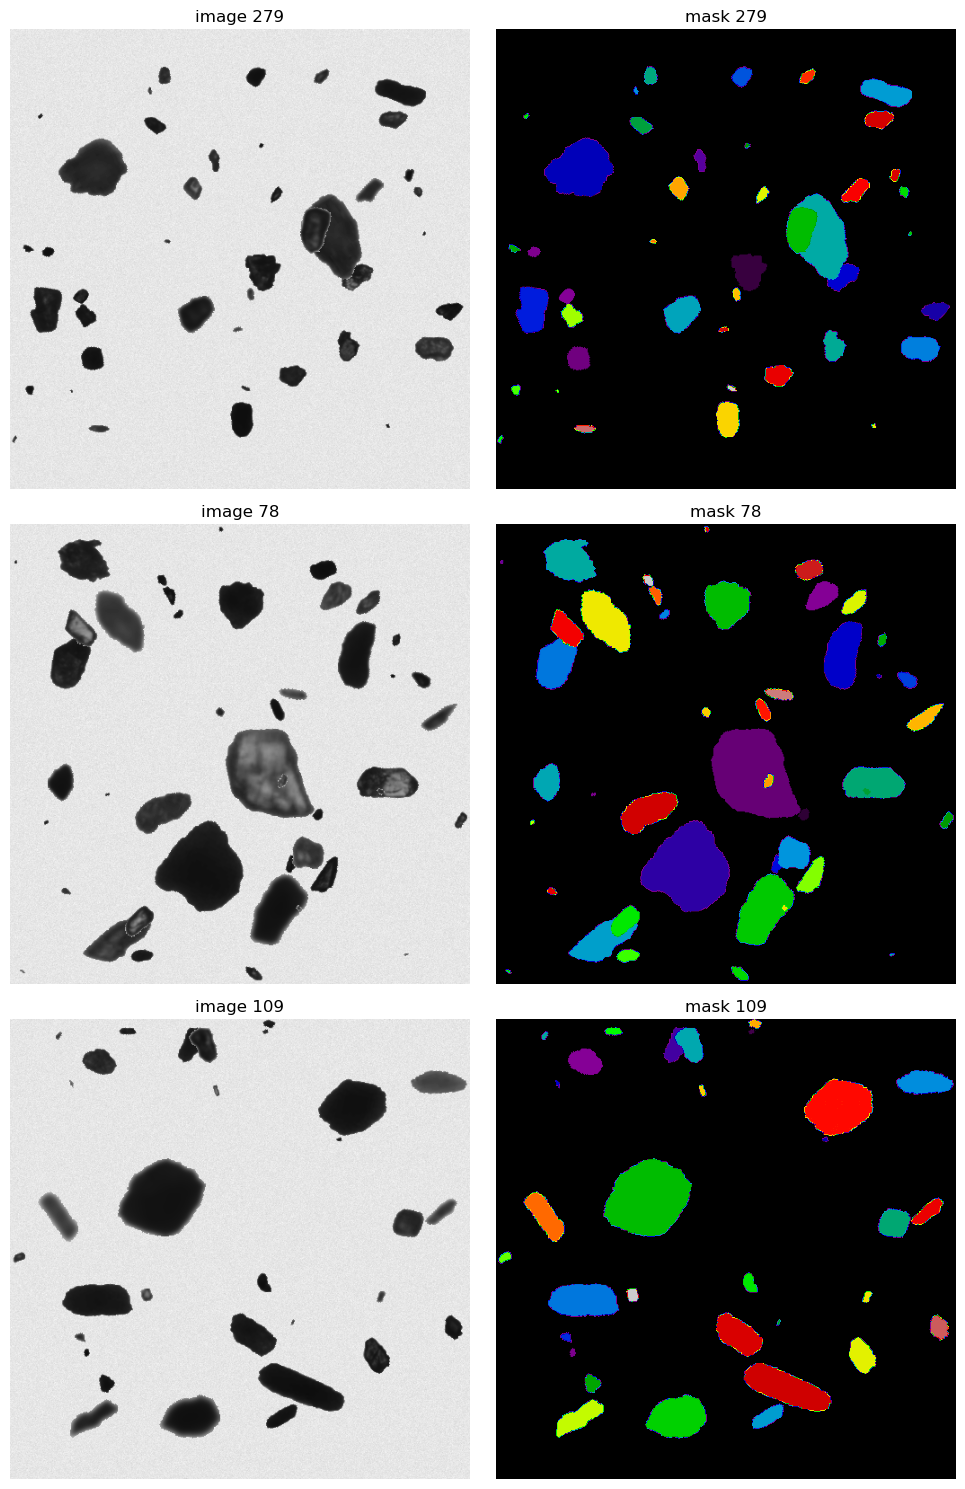

In [ ]:
# quick check of a few saved samples
from tifffile import imread

image_files = sorted(glob(f"{OUTPUT_IMAGE_FOLDER}/*.tif"))
mask_files = sorted(glob(f"{OUTPUT_MASK_FOLDER}/*.tif"))

n_show = 3
fig, axes = plt.subplots(n_show, 2, figsize=(10, 5 * n_show))
for row in range(n_show):
    idx = random.randint(0, len(image_files) - 1)
    img = imread(image_files[idx])
    msk = imread(mask_files[idx])
    axes[row, 0].imshow(img, cmap="gray", vmin=0, vmax=1); axes[row, 0].set_title(f"image {idx}"); axes[row, 0].axis("off")
    axes[row, 1].imshow(msk, cmap="nipy_spectral"); axes[row, 1].set_title(f"mask {idx}"); axes[row, 1].axis("off")
plt.tight_layout(); plt.show()
